# 🖼️ Finetuning con LoRA de Stable Diffusion v1.4 sobre ilustraciones de libros antiguos

**Máster en IA, Cloud Computing y DevOps · Modelos de Generación de Imagen · Entrega final**<br>
Autor: Antonio

**Objetivo.** Adaptar `CompVis/stable-diffusion-v1-4` al estilo de las ilustraciones de libros antiguos (grabados y litografías de los siglos XVIII-XX) del dataset [`gigant/oldbookillustrations`](https://huggingface.co/datasets/gigant/oldbookillustrations) con **LoRA** (*Low-Rank Adaptation*), subir el resultado a Hugging Face y comparar, con el mismo *prompt* y la misma semilla, la imagen **antes** y **después** del finetuning.

**Cómo ejecutarlo.** Necesita una **GPU NVIDIA** (Google Colab con GPU T4 gratuita, o una GPU local con ≥ 12 GB de VRAM). En Colab: *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU T4* y después *Ejecutar todo*. Con la configuración por defecto tarda **unos 45-60 minutos en una T4**: ~25-30 min de entrenamiento, ~10 min de experimentos y el resto en descargas, generación de imágenes y subida al Hub. En una GPU de escritorio reciente es bastante más rápido.

**Índice**

1. Instalación y configuración
2. Carga y exploración del dataset
3. Preprocesado: imágenes no cuadradas
4. Modelo base y adaptadores LoRA
5. Imágenes **antes** del finetuning
6. Entrenamiento
7. Guardar y subir a Hugging Face
8. Cargar el modelo desde Hugging Face e imágenes **después**
9. Comparación antes / después
10. Experimentos con hiperparámetros
11. Conclusiones

## 1. Instalación y configuración

In [1]:
# En Colab, torch ya viene instalado con soporte CUDA.
%pip install -q "diffusers==0.41.0" "transformers==5.19.0" "accelerate==1.15.0" "peft==0.21.2" "datasets==5.1.0" "huggingface_hub==1.33.0"

Note: you may need to restart the kernel to use updated packages.


In [2]:
import gc
import json
import math
import random
import time
from dataclasses import asdict, dataclass, replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from accelerate import Accelerator
from datasets import load_dataset
from diffusers import AutoencoderKL, DDPMScheduler, StableDiffusionPipeline, UNet2DConditionModel
from diffusers.optimization import get_scheduler
from diffusers.training_utils import cast_training_params
from diffusers.utils import convert_state_dict_to_diffusers
from peft import LoraConfig
from peft.utils import get_peft_model_state_dict
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from transformers import CLIPTextModel, CLIPTokenizer

assert torch.cuda.is_available(), "Este notebook necesita GPU (en Colab: Entorno de ejecución → GPU T4)"
DEVICE = "cuda"
print("GPU:", torch.cuda.get_device_name(0))
print("torch", torch.__version__)

GPU: NVIDIA GeForce RTX 5060 Ti
torch 2.14.1+cu130


**Hiperparámetros.** Todos están en un único `dataclass` para poder lanzar experimentos cambiando solo lo necesario (sección 10).

| Parámetro | Valor | Por qué |
|---|---|---|
| `n_samples` | 1000 | ~¼ del dataset (4154 imágenes). Suficiente para aprender el estilo sin descargar los 5 GB. |
| `resolution` | 512 | Resolución nativa de SD v1.4. |
| `train_batch_size` | 4 | Cabe en los 16 GB de una T4 con *gradient checkpointing* y fp16. |
| `num_epochs` | 3 | 750 pasos en total. Un estilo se aprende en unos cientos de pasos y más épocas sobreajustan a las imágenes concretas. |
| `learning_rate` | 1e-4 | Valor estándar para LoRA (bastante más alto que en un finetuning completo, ~1e-6), porque solo se entrenan unos pocos parámetros. |
| `lora_rank` (r) | 8 | Rango de las matrices de bajo rango. A mayor r, más capacidad y más parámetros. |
| `lora_alpha` | 8 | Escala de la actualización (ΔW · α/r). Con α = r la escala es 1. |
| `mixed_precision` | fp16 | Pesos congelados en fp16 y parámetros LoRA en fp32: la mitad de memoria y estable. |

In [3]:
@dataclass
class Config:
    # Modelo y datos
    model_id: str = "CompVis/stable-diffusion-v1-4"
    dataset_id: str = "gigant/oldbookillustrations"
    image_column: str = "1600px"      # imagen (1600 px de ancho o de alto)
    caption_column: str = "info_alt"  # descripción de la imagen
    n_samples: int = 1000
    # Preprocesado
    resolution: int = 512
    center_crop: bool = True
    random_flip: bool = True
    # Entrenamiento
    train_batch_size: int = 4
    gradient_accumulation_steps: int = 1
    num_epochs: int = 3
    max_train_steps: int | None = None  # si se fija, tiene prioridad sobre num_epochs
    learning_rate: float = 1e-4
    lr_scheduler: str = "cosine"
    lr_warmup_steps: int = 50
    max_grad_norm: float = 1.0
    mixed_precision: str = "fp16"
    gradient_checkpointing: bool = True
    # LoRA
    lora_rank: int = 8
    lora_alpha: int = 8
    lora_target_modules: tuple = ("to_k", "to_q", "to_v", "to_out.0")
    # Varios
    seed: int = 42
    output_dir: str = "lora-ilustraciones-antiguas"
    hub_model_id: str = "sd-v1-4-lora-ilustraciones-antiguas"


cfg = Config()
RESULTADOS = Path("resultados")
RESULTADOS.mkdir(exist_ok=True)
print(json.dumps(asdict(cfg), indent=2, ensure_ascii=False))

{
  "model_id": "CompVis/stable-diffusion-v1-4",
  "dataset_id": "gigant/oldbookillustrations",
  "image_column": "1600px",
  "caption_column": "info_alt",
  "n_samples": 1000,
  "resolution": 512,
  "center_crop": true,
  "random_flip": true,
  "train_batch_size": 4,
  "gradient_accumulation_steps": 1,
  "num_epochs": 3,
  "max_train_steps": null,
  "learning_rate": 0.0001,
  "lr_scheduler": "cosine",
  "lr_warmup_steps": 50,
  "max_grad_norm": 1.0,
  "mixed_precision": "fp16",
  "gradient_checkpointing": true,
  "lora_rank": 8,
  "lora_alpha": 8,
  "lora_target_modules": [
    "to_k",
    "to_q",
    "to_v",
    "to_out.0"
  ],
  "seed": 42,
  "output_dir": "lora-ilustraciones-antiguas",
  "hub_model_id": "sd-v1-4-lora-ilustraciones-antiguas"
}


In [4]:
def set_seed(seed: int) -> None:
    # Fija todas las semillas para que el experimento sea reproducible.
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(cfg.seed)

**Inicio de sesión en Hugging Face** (necesario para subir el modelo). Se necesita un *token* con permiso de escritura (*Settings → Access Tokens → New token → Write*). En Colab lo más cómodo es guardarlo como secreto `HF_TOKEN` (icono de la llave, a la izquierda). Si no, aparecerá un cuadro para pegarlo.

In [5]:
from huggingface_hub import HfApi, get_token, notebook_login

# Si no hay ningún token guardado (ni el secreto HF_TOKEN de Colab), lo pide.
if get_token() is None:
    notebook_login()
HF_USER = HfApi().whoami()["name"]
print("Sesión iniciada como:", HF_USER)

Sesión iniciada como: tmllabres


## 2. Carga y exploración del dataset

El dataset tiene 4154 ilustraciones y 25 columnas (unos 5 GB, porque incluye también el escaneo original `rawscan`). Solo me interesan **`1600px`** (la imagen) e **`info_alt`** (su descripción), así que lo cargo en **modo *streaming*** y leyendo **solo esas dos columnas**: así no descargo los escaneos originales ni el dataset entero, solo las `n_samples` primeras filas válidas.

Mientras se descargan, reduzco cada imagen para que su lado corto mida `resolution` píxeles. Una imagen de 1600 px ocupa ~6 MB descomprimida, así que guardar 1000 a tamaño original no cabría en la RAM de Colab.

In [6]:
def resize_shorter_side(img: Image.Image, size: int) -> Image.Image:
    # Redimensiona manteniendo la proporción para que el lado corto mida `size`.
    w, h = img.size
    scale = size / min(w, h)
    return img.resize((max(size, round(w * scale)), max(size, round(h * scale))), Image.BICUBIC)


t0 = time.time()
stream = load_dataset(cfg.dataset_id, split="train", streaming=True,
                      columns=[cfg.image_column, cfg.caption_column])
images, captions, original_sizes, descartadas = [], [], [], 0
for ex in stream:
    caption = (ex[cfg.caption_column] or "").strip()
    img = ex[cfg.image_column]
    if not caption or img is None:  # sin descripción o sin imagen: no sirve para entrenar
        descartadas += 1
        continue
    img = img.convert("RGB")
    original_sizes.append(img.size)
    images.append(resize_shorter_side(img, cfg.resolution))
    captions.append(caption)
    if len(images) >= cfg.n_samples:
        break
print(f"{len(images)} ejemplos cargados en {time.time() - t0:.0f} s · descartados por no tener descripción: {descartadas}")

1000 ejemplos cargados en 53 s · descartados por no tener descripción: 0


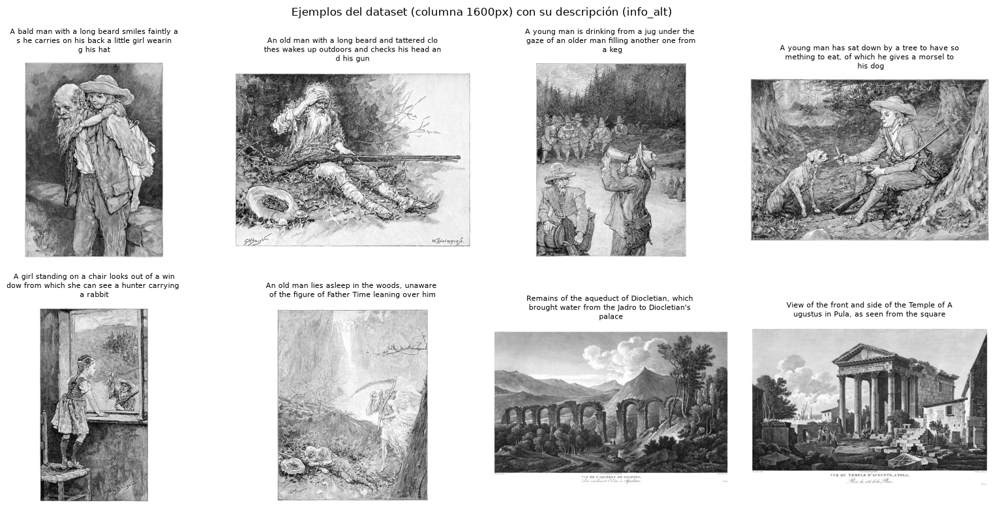

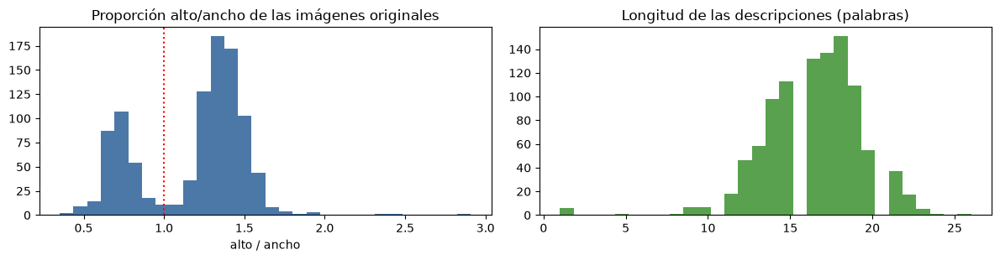

Imágenes verticales: 70% · horizontales: 29% · proporción alto/ancho entre 0.35 y 2.91
Descripciones: 16.4 palabras de media (máx. 26); el codificador CLIP admite 77 tokens, así que casi ninguna se trunca.


In [7]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, i in zip(axes.flat, range(8)):
    ax.imshow(images[i]); ax.axis("off")
    ax.set_title("\n".join([captions[i][j:j + 45] for j in range(0, min(len(captions[i]), 135), 45)]), fontsize=8)
plt.suptitle("Ejemplos del dataset (columna 1600px) con su descripción (info_alt)")
plt.tight_layout(); plt.show()

ws, hs = np.array(original_sizes).T
ratios = hs / ws
lens = [len(c.split()) for c in captions]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
axes[0].hist(ratios, bins=30, color="#4c78a8"); axes[0].axvline(1, color="red", ls=":")
axes[0].set_title("Proporción alto/ancho de las imágenes originales"); axes[0].set_xlabel("alto / ancho")
axes[1].hist(lens, bins=30, color="#59a14f"); axes[1].set_title("Longitud de las descripciones (palabras)")
plt.tight_layout(); plt.show()
print(f"Imágenes verticales: {(ratios > 1).mean():.0%} · horizontales: {(ratios < 1).mean():.0%} · "
      f"proporción alto/ancho entre {ratios.min():.2f} y {ratios.max():.2f}")
print(f"Descripciones: {np.mean(lens):.1f} palabras de media (máx. {max(lens)}); "
      f"el codificador CLIP admite 77 tokens, así que casi ninguna se trunca.")

## 3. Preprocesado: imágenes no cuadradas

Stable Diffusion v1.4 se entrenó con imágenes cuadradas de 512×512 y su VAE trabaja con lados múltiplos de 8. Como aquí **el ancho es siempre 1600 px pero el alto varía** (hay ilustraciones verticales y apaisadas), el preprocesado es:

1. **Redimensionar por el lado corto** a 512 manteniendo la proporción (hecho al cargar). Así no se deforma la ilustración, cosa que sí pasaría con un `Resize((512, 512))`.
2. **Recortar 512×512**: con un **recorte central** (`center_crop=True`) se conserva la parte principal de la escena, que en estas ilustraciones suele estar centrada; con un recorte aleatorio se aumentarían los datos a cambio de cortar a veces a los personajes.
3. **Volteo horizontal aleatorio** (aumento de datos barato; en ilustraciones no hay texto que se lea al revés salvo excepciones).
4. Pasar a tensor y **normalizar a [-1, 1]**, el rango que espera el VAE.

Las descripciones se tokenizan con el tokenizador CLIP del modelo (máximo 77 tokens, con *padding* y truncado).

Tensor de entrada: (3, 512, 512) rango [-1.00, 1.00]


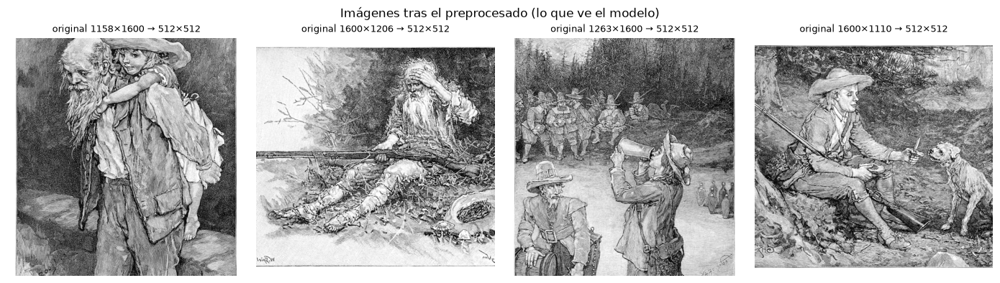

In [8]:
tokenizer = CLIPTokenizer.from_pretrained(cfg.model_id, subfolder="tokenizer")

train_transforms = transforms.Compose([
    transforms.Resize(cfg.resolution, interpolation=transforms.InterpolationMode.BILINEAR),  # por si acaso
    transforms.CenterCrop(cfg.resolution) if cfg.center_crop else transforms.RandomCrop(cfg.resolution),
    transforms.RandomHorizontalFlip() if cfg.random_flip else transforms.Lambda(lambda x: x),
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5]),
])


class IllustrationsDataset(Dataset):
    # Dataset de PyTorch con las imágenes ya reducidas y las descripciones tokenizadas.

    def __init__(self, images, captions):
        self.images = images
        self.input_ids = tokenizer(captions, max_length=tokenizer.model_max_length, padding="max_length",
                                   truncation=True, return_tensors="pt").input_ids

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        return {"pixel_values": train_transforms(self.images[idx]), "input_ids": self.input_ids[idx]}


def collate_fn(examples):
    pixel_values = torch.stack([e["pixel_values"] for e in examples]).contiguous().float()
    return {"pixel_values": pixel_values, "input_ids": torch.stack([e["input_ids"] for e in examples])}


train_dataset = IllustrationsDataset(images, captions)
sample = train_dataset[0]["pixel_values"]
print("Tensor de entrada:", tuple(sample.shape), f"rango [{sample.min():.2f}, {sample.max():.2f}]")

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, i in zip(axes, range(4)):
    ax.imshow((train_dataset[i]["pixel_values"].permute(1, 2, 0) * 0.5 + 0.5).clamp(0, 1)); ax.axis("off")
    ax.set_title(f"original {original_sizes[i][0]}×{original_sizes[i][1]} → {cfg.resolution}×{cfg.resolution}", fontsize=9)
plt.suptitle("Imágenes tras el preprocesado (lo que ve el modelo)"); plt.tight_layout(); plt.show()

## 4. Modelo base y adaptadores LoRA

Stable Diffusion tiene tres piezas: el **codificador de texto CLIP** (texto → *embeddings*), el **VAE** (imagen ↔ espacio latente de 64×64×4) y la **UNet**, que aprende a quitar ruido de los latentes condicionada por el texto.

**LoRA** congela todos los pesos originales y añade a ciertas capas lineales una actualización de bajo rango: en lugar de aprender ΔW (d×d), aprende **B·A** con A (r×d) y B (d×r), con r ≪ d. La salida pasa a ser W·x + (α/r)·B·A·x. Como en la práctica de clase, aplico LoRA a las proyecciones de atención de la UNet (`to_q`, `to_k`, `to_v`, `to_out.0`), que es donde el texto se cruza con la imagen (*cross-attention*) y donde mejor se captura un estilo.

In [9]:
def load_components(model_id: str):
    # Carga y congela VAE, codificador de texto y UNet del modelo base (pesos en fp16, la mitad de descarga).
    text_encoder = CLIPTextModel.from_pretrained(model_id, subfolder="text_encoder", variant="fp16")
    vae = AutoencoderKL.from_pretrained(model_id, subfolder="vae", variant="fp16")
    unet = UNet2DConditionModel.from_pretrained(model_id, subfolder="unet", variant="fp16")
    for m in (text_encoder, vae, unet):
        m.requires_grad_(False)
    return text_encoder, vae, unet


def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return trainable, total


_, _, unet_demo = load_components(cfg.model_id)
before = count_params(unet_demo)[1]
unet_demo.add_adapter(LoraConfig(r=cfg.lora_rank, lora_alpha=cfg.lora_alpha, init_lora_weights="gaussian",
                                 target_modules=list(cfg.lora_target_modules)))
trainable, total = count_params(unet_demo)
print(f"UNet: {before / 1e6:.1f} M parámetros congelados · LoRA r={cfg.lora_rank}: {trainable / 1e6:.2f} M entrenables "
      f"({trainable / before:.2%} de la UNet)")
print(f"Tamaño del archivo LoRA en fp32 ≈ {trainable * 4 / 1e6:.1f} MB (frente a ~3,4 GB de la UNet completa)")
del unet_demo; gc.collect(); torch.cuda.empty_cache()

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

C:\Users\tmlla\Desktop\Entrega Modelos Generacion Imagen\.venv\Lib\site-packages\huggingface_hub\utils\_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


UNet: 859.5 M parámetros congelados · LoRA r=8: 1.59 M entrenables (0.19% de la UNet)
Tamaño del archivo LoRA en fp32 ≈ 6.4 MB (frente a ~3,4 GB de la UNet completa)


## 5. Imágenes **antes** del finetuning

Genero con el **modelo base** varios *prompts* con una **semilla fija**. Después repetiré exactamente lo mismo con el modelo finetuneado, de modo que la única diferencia sea el LoRA. Los *prompts* describen escenas al estilo de las descripciones del dataset, sin mencionar ningún estilo artístico, y el último es un tema moderno, para ver si el estilo se transfiere a contenidos que no aparecen en el dataset.

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

4 imágenes en 11 s


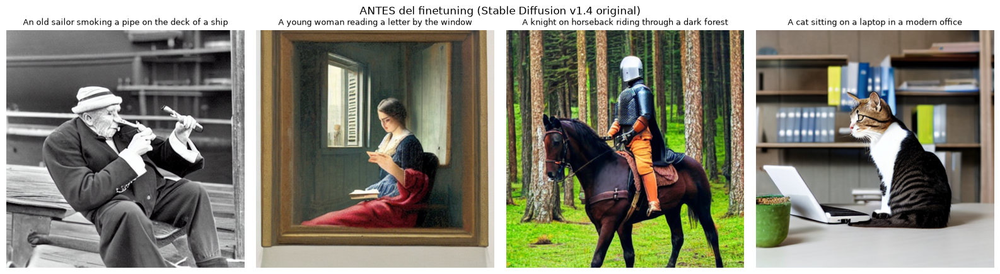

In [10]:
PROMPTS = [
    "An old sailor smoking a pipe on the deck of a ship",
    "A young woman reading a letter by the window",
    "A knight on horseback riding through a dark forest",
    "A cat sitting on a laptop in a modern office",
]
SEED = 1234
STEPS = 30
GUIDANCE = 7.5


def load_pipeline(model_id: str):
    pipe = StableDiffusionPipeline.from_pretrained(model_id, dtype=torch.float16, variant="fp16").to(DEVICE)
    pipe.set_progress_bar_config(disable=True)
    return pipe


def generate(pipe, prompts, seed=SEED, **kwargs):
    # Una imagen por prompt, cada una con su propio generador para que sea reproducible.
    out = []
    for p in prompts:
        g = torch.Generator(device=DEVICE).manual_seed(seed)
        out.append(pipe(p, num_inference_steps=STEPS, guidance_scale=GUIDANCE, generator=g,
                        height=cfg.resolution, width=cfg.resolution, **kwargs).images[0])
    return out


def show_row(imgs, titles, suptitle):
    fig, axes = plt.subplots(1, len(imgs), figsize=(4 * len(imgs), 4.4))
    for ax, im, t in zip(axes, imgs, titles):
        ax.imshow(im); ax.axis("off"); ax.set_title(t, fontsize=9, wrap=True)
    plt.suptitle(suptitle); plt.tight_layout(); plt.show()


pipe = load_pipeline(cfg.model_id)
t0 = time.time()
antes = generate(pipe, PROMPTS)
print(f"{len(antes)} imágenes en {time.time() - t0:.0f} s")
(RESULTADOS / "antes").mkdir(exist_ok=True)
for i, im in enumerate(antes):
    im.save(RESULTADOS / "antes" / f"prompt_{i + 1}.png")
show_row(antes, PROMPTS, "ANTES del finetuning (Stable Diffusion v1.4 original)")
del pipe; gc.collect(); torch.cuda.empty_cache()

## 6. Entrenamiento

Bucle de entrenamiento estándar de un modelo de difusión latente, basado en el *script* oficial de `diffusers` que vimos en clase:

1. El **VAE** codifica la imagen a latentes (×0,18215, el factor de escala de SD).
2. Se elige un **paso de tiempo t** aleatorio y se añade ruido gaussiano a los latentes según el *scheduler* DDPM.
3. El **codificador CLIP** convierte la descripción en *embeddings*.
4. La **UNet (con LoRA)** predice el ruido añadido y la pérdida es el **MSE** entre el ruido real y el predicho (SD v1.4 usa predicción ε).
5. Solo se actualizan los parámetros LoRA (AdamW, *learning rate* con *warmup* y decaimiento coseno, recorte de gradiente).

Lo encapsulo en una función para reutilizarla en los experimentos de la sección 10.

In [11]:
def train_lora(cfg: Config, dataset: Dataset, log_every: int = 25):
    # Entrena un LoRA sobre la UNet y devuelve (state_dict LoRA en formato diffusers, pérdidas, segundos).
    set_seed(cfg.seed)
    accelerator = Accelerator(gradient_accumulation_steps=cfg.gradient_accumulation_steps,
                              mixed_precision=cfg.mixed_precision)
    noise_scheduler = DDPMScheduler.from_pretrained(cfg.model_id, subfolder="scheduler")
    text_encoder, vae, unet = load_components(cfg.model_id)

    weight_dtype = torch.float16 if accelerator.mixed_precision == "fp16" else torch.float32
    for m in (text_encoder, vae, unet):
        m.to(accelerator.device, dtype=weight_dtype)  # pesos congelados en fp16 (la mitad de memoria)

    unet.add_adapter(LoraConfig(r=cfg.lora_rank, lora_alpha=cfg.lora_alpha, init_lora_weights="gaussian",
                                target_modules=list(cfg.lora_target_modules)))
    if cfg.mixed_precision == "fp16":
        cast_training_params(unet, dtype=torch.float32)  # los parámetros LoRA se entrenan en fp32
    if cfg.gradient_checkpointing:
        unet.enable_gradient_checkpointing()
    lora_params = [p for p in unet.parameters() if p.requires_grad]

    optimizer = torch.optim.AdamW(lora_params, lr=cfg.learning_rate, betas=(0.9, 0.999), weight_decay=1e-2, eps=1e-8)
    loader = DataLoader(dataset, shuffle=True, collate_fn=collate_fn, batch_size=cfg.train_batch_size,
                        num_workers=0, drop_last=True)
    steps_per_epoch = math.ceil(len(loader) / cfg.gradient_accumulation_steps)
    max_steps = cfg.max_train_steps or cfg.num_epochs * steps_per_epoch
    num_epochs = math.ceil(max_steps / steps_per_epoch)
    lr_scheduler = get_scheduler(cfg.lr_scheduler, optimizer=optimizer, num_warmup_steps=cfg.lr_warmup_steps,
                                 num_training_steps=max_steps)
    unet, optimizer, loader, lr_scheduler = accelerator.prepare(unet, optimizer, loader, lr_scheduler)

    print(f"Entrenando: {len(dataset)} ejemplos · batch {cfg.train_batch_size} · {num_epochs} épocas · "
          f"{max_steps} pasos · r={cfg.lora_rank}")
    losses, step, t0 = [], 0, time.time()
    unet.train()
    for epoch in range(num_epochs):
        for batch in loader:
            with accelerator.accumulate(unet):
                latents = vae.encode(batch["pixel_values"].to(dtype=weight_dtype)).latent_dist.sample()
                latents = latents * vae.config.scaling_factor
                noise = torch.randn_like(latents)
                timesteps = torch.randint(0, noise_scheduler.config.num_train_timesteps, (latents.shape[0],),
                                          device=latents.device).long()
                noisy_latents = noise_scheduler.add_noise(latents, noise, timesteps)
                encoder_hidden_states = text_encoder(batch["input_ids"], return_dict=False)[0]
                model_pred = unet(noisy_latents, timesteps, encoder_hidden_states, return_dict=False)[0]
                loss = F.mse_loss(model_pred.float(), noise.float(), reduction="mean")
                accelerator.backward(loss)
                if accelerator.sync_gradients:
                    accelerator.clip_grad_norm_(lora_params, cfg.max_grad_norm)
                optimizer.step(); lr_scheduler.step(); optimizer.zero_grad()
            if accelerator.sync_gradients:
                step += 1
                losses.append(loss.detach().item())
                if step % log_every == 0 or step == 1:
                    print(f"  paso {step:4d}/{max_steps} · época {epoch + 1} · loss {np.mean(losses[-log_every:]):.4f} · "
                          f"lr {lr_scheduler.get_last_lr()[0]:.2e} · {time.time() - t0:.0f} s")
            if step >= max_steps:
                break
        if step >= max_steps:
            break

    unet = accelerator.unwrap_model(unet).to(torch.float32)
    lora_state = convert_state_dict_to_diffusers(get_peft_model_state_dict(unet))
    elapsed = time.time() - t0
    del unet, vae, text_encoder, optimizer
    gc.collect(); torch.cuda.empty_cache()
    return lora_state, losses, elapsed

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


Entrenando: 1000 ejemplos · batch 4 · 3 épocas · 750 pasos · r=8


  paso    1/750 · época 1 · loss 0.4342 · lr 2.00e-06 · 1 s


...

  paso  700/750 · época 3 · loss 0.1639 · lr 1.25e-06 · 543 s


  paso  725/750 · época 3 · loss 0.1807 · lr 3.14e-07 · 562 s


There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  paso  750/750 · época 3 · loss 0.1404 · lr 0.00e+00 · 582 s



Entrenamiento terminado en 9.7 min · 750 pasos
Memoria GPU máxima: 4.0 GB


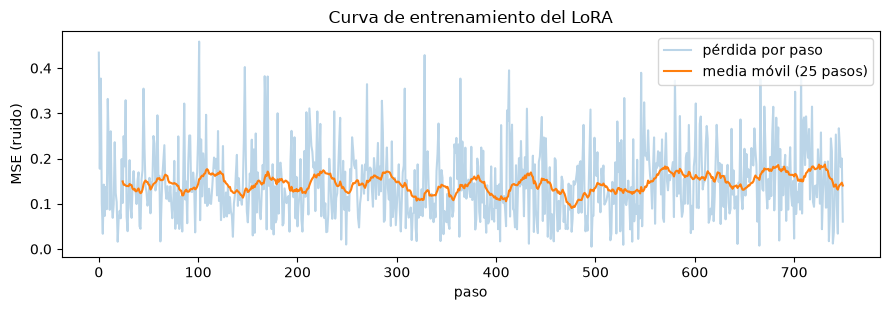

In [12]:
lora_state, losses, train_seconds = train_lora(cfg, train_dataset)
print(f"\nEntrenamiento terminado en {train_seconds / 60:.1f} min · {len(losses)} pasos")
print(f"Memoria GPU máxima: {torch.cuda.max_memory_allocated() / 1e9:.1f} GB")

window = max(1, len(losses) // 30)
smooth = np.convolve(losses, np.ones(window) / window, mode="valid")
plt.figure(figsize=(9, 3.2))
plt.plot(losses, alpha=0.3, label="pérdida por paso")
plt.plot(range(window - 1, len(losses)), smooth, label=f"media móvil ({window} pasos)")
plt.xlabel("paso"); plt.ylabel("MSE (ruido)"); plt.title("Curva de entrenamiento del LoRA"); plt.legend()
plt.tight_layout(); plt.savefig(RESULTADOS / "curva_entrenamiento.png", dpi=130); plt.show()

> **Cómo leer la curva.** En difusión la pérdida es **muy ruidosa**, porque cada paso usa un nivel de ruido t aleatorio: con t pequeño la tarea es fácil y con t grande, difícil. Por eso miro la media móvil y, sobre todo, las imágenes generadas. Una pérdida que apenas baja es normal: el modelo base ya sabe quitar ruido, y el LoRA solo ajusta el *estilo*.

## 7. Guardar y subir a Hugging Face

Guardo los pesos LoRA en el formato estándar de `diffusers` (`pytorch_lora_weights.safetensors`, unos pocos MB) junto con una *model card* (`README.md`) con los metadatos, los hiperparámetros y las imágenes antes/después. Subo dos repositorios:

- **LoRA** (`<usuario>/sd-v1-4-lora-ilustraciones-antiguas`): solo el adaptador, que se carga encima del modelo base con `pipe.load_lora_weights(...)`.
- **Modelo completo finetuneado** (`<usuario>/sd-v1-4-ilustraciones-antiguas`): el modelo base con el LoRA **fusionado** en sus pesos (`fuse_lora`), que se carga directamente con `StableDiffusionPipeline.from_pretrained(...)`.

In [13]:
out_dir = Path(cfg.output_dir)
out_dir.mkdir(exist_ok=True)
StableDiffusionPipeline.save_lora_weights(save_directory=out_dir, unet_lora_layers=lora_state, safe_serialization=True)
(out_dir / "training_config.json").write_text(json.dumps(
    {**asdict(cfg), "steps": len(losses), "train_minutes": round(train_seconds / 60, 1),
     "final_loss_avg_last50": float(np.mean(losses[-50:]))}, indent=2, ensure_ascii=False))
print("Archivos:", [f"{p.name} ({p.stat().st_size / 1e6:.1f} MB)" for p in out_dir.iterdir()])

REPO_LORA = f"{HF_USER}/{cfg.hub_model_id}"
REPO_FULL = f"{HF_USER}/{cfg.hub_model_id.replace('-lora', '')}"

Archivos: ['pytorch_lora_weights.safetensors (6.4 MB)', 'README.md (0.0 MB)', 'training_config.json (0.0 MB)']


In [14]:
def model_card(repo_id: str, full: bool) -> str:
    # README.md del repositorio en Hugging Face: metadatos (YAML), descripción y ejemplo de uso.
    if full:
        titulo = "modelo finetuneado (LoRA fusionado)"
        uso = f'pipe = StableDiffusionPipeline.from_pretrained("{repo_id}", torch_dtype=torch.float16).to("cuda")'
    else:
        titulo = "LoRA"
        uso = (f'pipe = StableDiffusionPipeline.from_pretrained("{cfg.model_id}", torch_dtype=torch.float16).to("cuda")\n'
               f'pipe.load_lora_weights("{repo_id}")')
    return f'''---
base_model: {cfg.model_id}
library_name: diffusers
license: creativeml-openrail-m
datasets:
- {cfg.dataset_id}
tags:
- stable-diffusion
- text-to-image
- diffusers
- lora
---

# Stable Diffusion v1.4 · {titulo} · ilustraciones de libros antiguos

Finetuning con LoRA de `{cfg.model_id}` con {len(train_dataset)} ilustraciones del dataset
[`{cfg.dataset_id}`](https://huggingface.co/datasets/{cfg.dataset_id}) (columnas `{cfg.image_column}` e `{cfg.caption_column}`).

Entrega final del módulo *Modelos de Generación de Imagen* del Máster en IA, Cloud Computing y DevOps (Pontia).

## Uso

```python
import torch
from diffusers import StableDiffusionPipeline

{uso}
image = pipe("An old sailor smoking a pipe on the deck of a ship", num_inference_steps=30).images[0]
```

## Entrenamiento

- {len(train_dataset)} imágenes, redimensionadas por el lado corto a {cfg.resolution} px y con recorte central de {cfg.resolution}×{cfg.resolution}
- {len(losses)} pasos ({cfg.num_epochs} épocas), batch {cfg.train_batch_size}, learning rate {cfg.learning_rate}
- LoRA con r = {cfg.lora_rank} y alpha = {cfg.lora_alpha} en {", ".join(cfg.lora_target_modules)}
- {train_seconds / 60:.1f} min en una {torch.cuda.get_device_name(0)}

## Antes / después (mismo prompt y semilla)

![antes y después](antes_despues.png)
'''


api = HfApi()
api.create_repo(REPO_LORA, exist_ok=True)
(out_dir / "README.md").write_text(model_card(REPO_LORA, full=False), encoding="utf-8")
api.upload_folder(repo_id=REPO_LORA, folder_path=str(out_dir), commit_message="LoRA ilustraciones antiguas")
print("LoRA subido:", f"https://huggingface.co/{REPO_LORA}")

LoRA subido: https://huggingface.co/tmllabres/sd-v1-4-lora-ilustraciones-antiguas


In [15]:
# Modelo completo: base + LoRA fusionado en los pesos (se carga sin necesidad de load_lora_weights).
full_dir = Path(cfg.output_dir + "-fusionado")
pipe = load_pipeline(cfg.model_id)
pipe.load_lora_weights(str(out_dir))
pipe.fuse_lora(lora_scale=1.0)
pipe.unload_lora_weights()  # quita las capas LoRA ya fusionadas para guardar un modelo "normal"
pipe.save_pretrained(full_dir, safe_serialization=True)
(full_dir / "README.md").write_text(model_card(REPO_FULL, full=True), encoding="utf-8")
api.create_repo(REPO_FULL, exist_ok=True)
api.upload_folder(repo_id=REPO_FULL, folder_path=str(full_dir), commit_message="Modelo SD v1.4 con LoRA fusionado")
print("Modelo completo subido:", f"https://huggingface.co/{REPO_FULL}")
del pipe; gc.collect(); torch.cuda.empty_cache()

Path("enlace_huggingface.txt").write_text(
    "Modelo finetuneado con LoRA (Stable Diffusion v1.4 + ilustraciones de libros antiguos)\n\n"
    f"LoRA: https://huggingface.co/{REPO_LORA}\n"
    f"Modelo completo (LoRA fusionado): https://huggingface.co/{REPO_FULL}\n",
    encoding="utf-8")
print(Path("enlace_huggingface.txt").read_text(encoding="utf-8"))

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Modelo completo subido: https://huggingface.co/tmllabres/sd-v1-4-ilustraciones-antiguas


Modelo finetuneado con LoRA (Stable Diffusion v1.4 + ilustraciones de libros antiguos)

LoRA: https://huggingface.co/tmllabres/sd-v1-4-lora-ilustraciones-antiguas
Modelo completo (LoRA fusionado): https://huggingface.co/tmllabres/sd-v1-4-ilustraciones-antiguas



## 8. Cargar el modelo desde Hugging Face e imágenes **después**

Como en clase, cargo el modelo base y le añado **el LoRA descargado del Hub** (no el que tengo en memoria), para comprobar que lo subido funciona. Genero los mismos *prompts* con la misma semilla.

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

pytorch_lora_weights.safetensors: reconstructing file:   0%|          |  0.00B / 6.41MB            

pytorch_lora_weights.safetensors: downloading bytes:           |  0.00B            

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


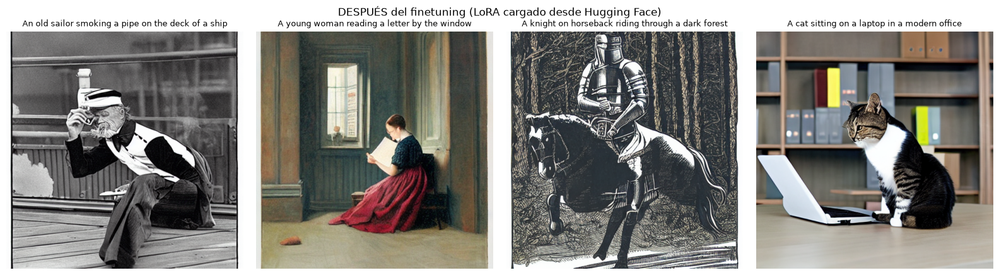

In [16]:
pipe = load_pipeline(cfg.model_id)
pipe.load_lora_weights(REPO_LORA)  # el LoRA recién subido al Hub
despues = generate(pipe, PROMPTS)
(RESULTADOS / "despues").mkdir(exist_ok=True)
for i, im in enumerate(despues):
    im.save(RESULTADOS / "despues" / f"prompt_{i + 1}.png")
show_row(despues, PROMPTS, "DESPUÉS del finetuning (LoRA cargado desde Hugging Face)")

**Intensidad del LoRA.** El peso del adaptador se puede escalar al generar (`cross_attention_kwargs={"scale": s}`): 0 equivale al modelo original y 1 al LoRA completo. Es una forma visual de ver qué aporta el finetuning.

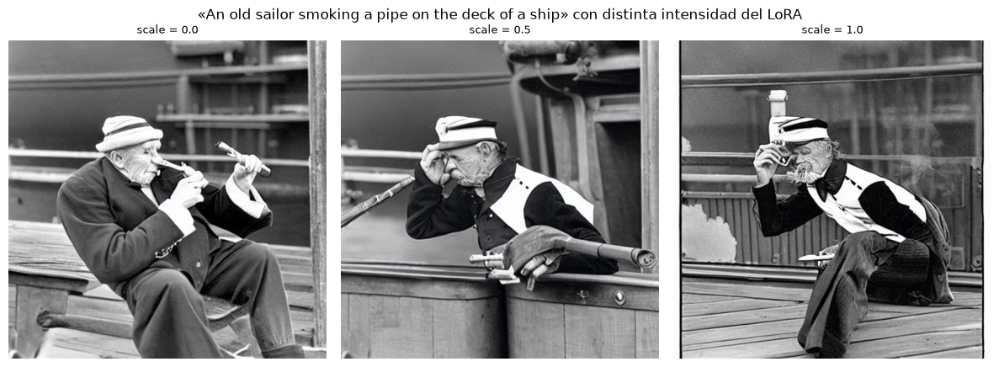

In [17]:
scales = [0.0, 0.5, 1.0]
imgs = [generate(pipe, [PROMPTS[0]], cross_attention_kwargs={"scale": s})[0] for s in scales]
show_row(imgs, [f"scale = {s}" for s in scales], f"«{PROMPTS[0]}» con distinta intensidad del LoRA")
grid = Image.new("RGB", (cfg.resolution * len(imgs), cfg.resolution), "white")
for i, im in enumerate(imgs):
    grid.paste(im.resize((cfg.resolution, cfg.resolution)), (i * cfg.resolution, 0))
grid.save(RESULTADOS / "escala_lora.png")

## 9. Comparación antes / después

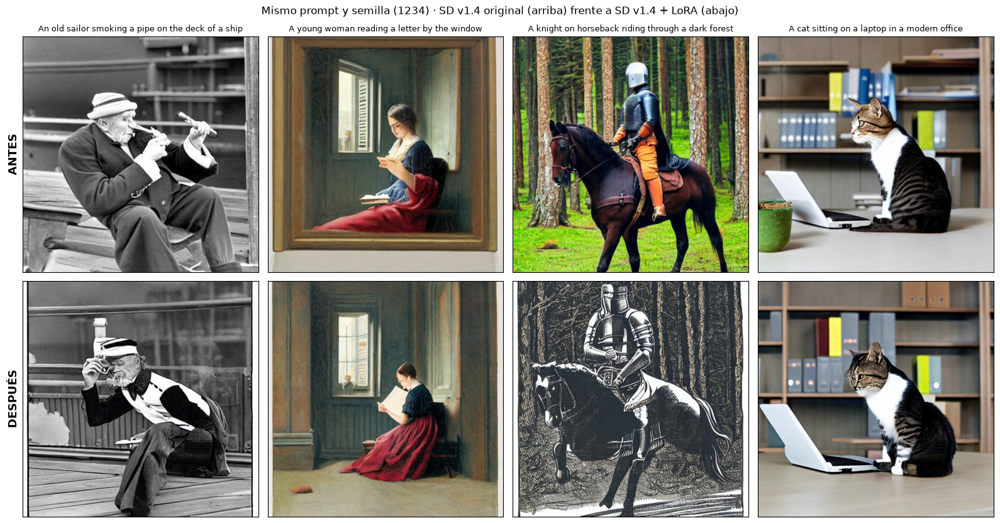

Guardado en C:\Users\tmlla\Desktop\Entrega Modelos Generacion Imagen\resultados


Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

Validating:           |   0%            

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

Validating:           |   0%            

In [18]:
def comparison_grid(antes, despues, prompts, path):
    # Rejilla con una fila «antes» y otra «después» para los mismos prompts y semilla.
    n = len(prompts)
    fig, axes = plt.subplots(2, n, figsize=(4 * n, 8.6))
    for j in range(n):
        for i, (imgs, label) in enumerate([(antes, "ANTES"), (despues, "DESPUÉS")]):
            ax = axes[i, j]
            ax.imshow(imgs[j]); ax.set_xticks([]); ax.set_yticks([])
            if j == 0:
                ax.set_ylabel(label, fontsize=13, fontweight="bold")
            if i == 0:
                ax.set_title(prompts[j], fontsize=9, wrap=True)
    plt.suptitle(f"Mismo prompt y semilla ({SEED}) · SD v1.4 original (arriba) frente a SD v1.4 + LoRA (abajo)", fontsize=12)
    plt.tight_layout(); plt.savefig(path, dpi=110); plt.show()


comparison_grid(antes, despues, PROMPTS, RESULTADOS / "antes_despues.png")

# Ejemplo principal que pide el enunciado: una imagen antes y otra después con el mismo prompt.
pair = Image.new("RGB", (cfg.resolution * 2 + 16, cfg.resolution), "white")
pair.paste(antes[0], (0, 0)); pair.paste(despues[0], (cfg.resolution + 16, 0))
pair.save(RESULTADOS / "ejemplo_antes_despues.png")
print("Guardado en", RESULTADOS.resolve())

# Añade la comparación a la model card de los dos repositorios del Hub
for repo in (REPO_LORA, REPO_FULL):
    api.upload_file(path_or_fileobj=str(RESULTADOS / "antes_despues.png"), path_in_repo="antes_despues.png",
                    repo_id=repo)
del pipe; gc.collect(); torch.cuda.empty_cache()

## 10. Experimentos con hiperparámetros

El enunciado propone jugar con el número de muestras, el *batch*, las épocas y el rango **r**. Para que quepa en una sesión de Colab hago una comparación **controlada y corta**: mismo número de pasos (150), mismos datos (300 imágenes) y mismo *prompt* y semilla, cambiando **solo r**. Así se ve el efecto de la capacidad del adaptador sobre el tiempo, el tamaño y el resultado.

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


Entrenando: 300 ejemplos · batch 4 · 2 épocas · 150 pasos · r=4


  paso    1/150 · época 1 · loss 0.4070 · lr 2.00e-06 · 1 s


...

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


,r,parámetros_LoRA_M,MB_fp32,minutos,loss_media_últimos_50
0,4,0.80,3.2,1.9,0.1447
1,32,6.38,25.5,1.9,0.1419
2,"8 (modelo final, 750 pasos, 1000 imágenes)",1.59,6.4,9.7,0.1605


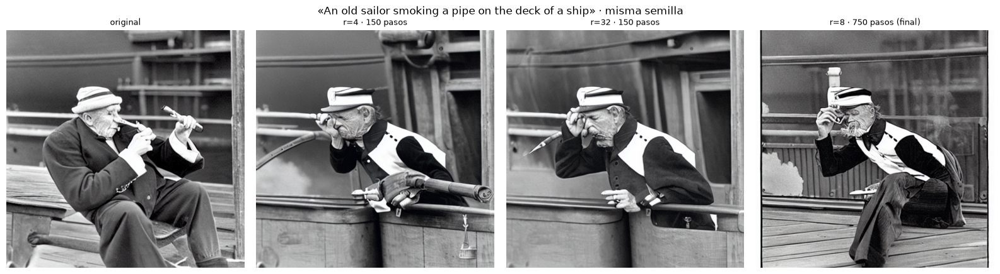

In [19]:
exp_dataset = IllustrationsDataset(images[:300], captions[:300])
exp_results = []
exp_images = []
for r in (4, 32):
    exp_cfg = replace(cfg, lora_rank=r, lora_alpha=r, max_train_steps=150, output_dir=f"exp-r{r}")
    state, exp_losses, secs = train_lora(exp_cfg, exp_dataset, log_every=50)
    n_params = sum(v.numel() for v in state.values())
    StableDiffusionPipeline.save_lora_weights(save_directory=exp_cfg.output_dir, unet_lora_layers=state)
    pipe = load_pipeline(cfg.model_id)
    pipe.load_lora_weights(exp_cfg.output_dir)
    exp_images.append(generate(pipe, [PROMPTS[0]])[0])
    exp_results.append({"r": r, "parámetros_LoRA_M": round(n_params / 1e6, 2), "MB_fp32": round(n_params * 4 / 1e6, 1),
                        "minutos": round(secs / 60, 1), "loss_media_últimos_50": round(float(np.mean(exp_losses[-50:])), 4)})
    del pipe, state; gc.collect(); torch.cuda.empty_cache()

n_final = sum(v.numel() for v in lora_state.values())
exp_results.append({"r": f"{cfg.lora_rank} (modelo final, {len(losses)} pasos, {len(train_dataset)} imágenes)",
                    "parámetros_LoRA_M": round(n_final / 1e6, 2), "MB_fp32": round(n_final * 4 / 1e6, 1),
                    "minutos": round(train_seconds / 60, 1),
                    "loss_media_últimos_50": round(float(np.mean(losses[-50:])), 4)})
display(pd.DataFrame(exp_results))
show_row([antes[0]] + exp_images + [despues[0]],
         ["original", "r=4 · 150 pasos", "r=32 · 150 pasos", f"r={cfg.lora_rank} · {len(losses)} pasos (final)"],
         f"«{PROMPTS[0]}» · misma semilla")
plt.close("all")

## 11. Conclusiones

- **Efecto del finetuning:** con el mismo prompt y la misma semilla, el LoRA acerca las imágenes al estilo del dataset. El caso más claro es el caballero: el modelo original genera una foto a color y con el LoRA sale un grabado en blanco y negro, con rayado y un marco alrededor, muy parecido a las ilustraciones del dataset. En el marinero la imagen ya era en blanco y negro antes, pero después aparece el borde blanco de las láminas de los libros y se parece más a una ilustración antigua. La mujer leyendo sigue en color y con un estilo de pintura parecido al original, así que ahí el cambio es pequeño.
- **Transferencia del estilo a un tema moderno (gato con portátil):** prácticamente no cambia. Creo que es porque en el dataset no hay nada parecido a un portátil o a una oficina, y el modelo base asocia mucho esos conceptos a fotos modernas. Con 750 pasos y r = 8 el LoRA no tiene fuerza suficiente para cambiar eso.
- **Intensidad del LoRA (scale 0 → 1):** con scale = 0 sale la misma imagen que con el modelo original, con 0,5 ya cambia la composición y con 1 aparece el estilo completo (el borde y el personaje más parecido a un grabado). Sirve para comprobar que el cambio viene del LoRA.
- **Experimentos con r:** con 300 imágenes y 150 pasos, r = 4 y r = 32 dan imágenes muy parecidas, casi la misma pérdida (0,145 y 0,142) y tardan lo mismo (1,9 min). La diferencia está en el tamaño: r = 32 tiene 8 veces más parámetros (6,4 M frente a 0,8 M, 25,5 MB frente a 3,2 MB). Con tan poco entrenamiento subir r no aporta nada; influye más entrenar más pasos con más imágenes, y de hecho solo el modelo final (r = 8, 750 pasos, 1000 imágenes) llega a aprender el borde de las láminas.
- **Curva de pérdida:** la pérdida oscila entre 0,1 y 0,2 durante todo el entrenamiento y la media móvil apenas baja. Es normal en difusión porque cada paso usa un nivel de ruido aleatorio, así que para ver si el entrenamiento funciona hay que fijarse en las imágenes.
- **Limitaciones:** las descripciones de `info_alt` describen la escena pero no el estilo, así que el modelo aprende el estilo de forma implícita y lo aplica a todo; el recorte central puede cortar ilustraciones muy verticales; con 1000 imágenes y pocas épocas, el modelo no memoriza ilustraciones concretas, pero con más épocas podría hacerlo.

---
**Descargar los resultados (Colab).** Esta celda comprime la carpeta `resultados/`, el `enlace_huggingface.txt` y la configuración de entrenamiento para copiarlos al repositorio de GitHub. Descarga también el notebook ejecutado: *Archivo → Descargar → Descargar .ipynb*.

In [20]:
import zipfile

# Comprime solo lo necesario para la entrega
with zipfile.ZipFile("entrega_resultados.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for path in list(RESULTADOS.rglob("*")) + [Path("enlace_huggingface.txt"), Path(cfg.output_dir) / "training_config.json"]:
        if path.is_file():
            z.write(path)
print("Creado entrega_resultados.zip")
try:
    from google.colab import files
    files.download("entrega_resultados.zip")
except ImportError:
    pass  # fuera de Colab el zip queda en la carpeta actual

Creado entrega_resultados.zip
